# GCC128 — Inteligência Artificial
## Trabalho Prático 04 — Agentes Inteligentes

### Assistente de Planejamento de Viagens

Uma **equipe de agentes** que ajuda a planejar uma viagem: pesquisa o destino, consulta a
previsão do tempo, estima custos e escreve a recomendação final.

O ponto central da aplicação é que **a ordem em que os agentes trabalham não está escrita no
código**. Um agente *supervisor* lê o pedido e decide, a cada rodada, qual especialista deve
agir. Pedidos diferentes produzem rotas diferentes — é isso que separa um **agente** de um
**pipeline**.

**Framework:** LangGraph · **LLM:** Groq (`openai/gpt-oss-20b`, gratuito)

Pyêtro Augusto Malaquias e Matheus Gomes Monteiro

---
## 1. Instalação e chave de acesso

O Groq oferece um plano gratuito. Crie uma chave em
[console.groq.com](https://console.groq.com) → *API Keys* → *Create API Key*.

> A chave é pedida com `getpass`, que não a exibe na tela. Nunca escreva a chave direto no
> notebook: se o arquivo for compartilhado, a chave vai junto.

In [1]:
!pip install -q langgraph langchain langchain-groq wikipedia

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 8.6 MB/s eta 0:00:00


In [2]:
import os
from getpass import getpass

os.environ["GROQ_API_KEY"] = getpass("Cole sua Groq API Key: ")
print("Chave configurada.")

Cole sua Groq API Key: ··········
Chave configurada.


---
## 2. Imports e o modelo

| Import | Para que serve |
|---|---|
| `StateGraph` | monta o grafo da equipe |
| `MessagesState` | estado com histórico de mensagens que acumula |
| `START`, `END` | nós de entrada e saída do grafo |
| `create_agent` | cria cada especialista (um agente completo) |
| `@tool` | transforma uma função Python em ferramenta do agente |

In [3]:
import warnings
warnings.filterwarnings("ignore")

import requests
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langchain_groq import ChatGroq
from langchain.agents import create_agent
from langgraph.graph import StateGraph, MessagesState, START, END

MODELO = "openai/gpt-oss-20b"   # gratuito no Groq e estavel para tool calling
LIMITE_PASSOS = 15              # protecao contra loop infinito no grafo

llm = ChatGroq(model=MODELO, temperature=0)
print("LLM pronto:", MODELO)

LLM pronto: openai/gpt-oss-20b


---
## 3. As ferramentas

Ferramentas são funções Python comuns com o decorator `@tool`. O decorator registra a função
e expõe ao LLM duas coisas: as **type hints**, que dizem *como* chamar, e o **docstring**, que
diz *quando* usar.

O docstring é a única informação que o modelo tem na hora de escolher a ferramenta. Por isso
cada um abaixo declara explicitamente o que a função faz, quando deve ser acionada e dá
exemplos de entrada.

Duas das três ferramentas consultam serviços reais e **nenhuma exige chave de API**:

| Ferramenta | Fonte | Papel na viagem |
|---|---|---|
| `buscar_destino` | Wikipédia (pt) | o que o destino oferece |
| `consultar_clima` | Open-Meteo | previsão e o que levar na mala |
| `calcular` | local | orçamento e divisão de despesas |

In [4]:
@tool
def buscar_destino(destino: str) -> str:
    """
    Busca informacoes gerais sobre uma cidade ou ponto turistico na Wikipedia
    em portugues: historia, localizacao, atracoes e caracteristicas.
    Use quando o usuario quiser saber o que um destino tem a oferecer.
    Exemplos: 'Ouro Preto', 'Cristo Redentor', 'Serra da Canastra'
    """
    try:
        import wikipedia
        wikipedia.set_lang("pt")
        return wikipedia.summary(destino, sentences=4)
    except Exception as erro:
        # Termo ambiguo: a excecao traz sugestoes, usamos a primeira
        opcoes = getattr(erro, "options", None)
        if opcoes:
            try:
                import wikipedia
                return wikipedia.summary(opcoes[0], sentences=4)
            except Exception:
                pass
        return f"Nao encontrei informacoes sobre '{destino}' na Wikipedia."

In [5]:
@tool
def consultar_clima(cidade: str) -> str:
    """
    Consulta a temperatura atual e a previsao dos proximos 3 dias de uma cidade,
    usando a API publica Open-Meteo (nao exige chave).
    Use quando a viagem depender do tempo: o que levar na mala, se vai chover,
    se a temperatura esta agradavel.
    Exemplos: 'Lavras', 'Ouro Preto', 'Florianopolis'
    """
    try:
        geo = requests.get(
            "https://geocoding-api.open-meteo.com/v1/search",
            params={"name": cidade, "count": 5, "language": "pt",
                    "countryCode": "BR"},
            timeout=20,
        ).json()

        achados = geo.get("results") or []
        if not achados:
            return f"Cidade '{cidade}' nao encontrada."

        # Prefere o nome exato: evita cair em homonimos de outro estado
        exatos = [r for r in achados if r["name"].lower() == cidade.strip().lower()]
        local = (exatos or achados)[0]
        previsao = requests.get(
            "https://api.open-meteo.com/v1/forecast",
            params={
                "latitude": local["latitude"],
                "longitude": local["longitude"],
                "current": "temperature_2m",
                "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
                "forecast_days": 3,
                "timezone": "auto",
            },
            timeout=20,
        ).json()

        agora = previsao["current"]["temperature_2m"]
        dias = previsao["daily"]
        linhas = [f"Temperatura atual em {local['name']}: {agora} C"]
        for i, data in enumerate(dias["time"]):
            linhas.append(
                f"  {data}: minima {dias['temperature_2m_min'][i]} C, "
                f"maxima {dias['temperature_2m_max'][i]} C, "
                f"chuva prevista {dias['precipitation_sum'][i]} mm"
            )
        return "\n".join(linhas)

    except Exception as erro:
        return f"Erro ao consultar o clima de '{cidade}': {erro}"

In [6]:
@tool
def calcular(expressao: str) -> str:
    """
    Calcula expressoes matematicas para estimar custos de viagem:
    combustivel, diarias, divisao de despesas entre pessoas.
    Use sempre que houver conta a fazer, em vez de estimar de cabeca.
    Exemplos: '320 / 12 * 6.10', '450 * 3', '(280 + 150) / 4'
    """
    try:
        # __builtins__ vazio bloqueia funcoes perigosas (import, open, exec)
        resultado = eval(expressao, {"__builtins__": {}}, {})
        return f"Resultado: {resultado}"
    except Exception as erro:
        return f"Erro ao calcular '{expressao}': {erro}"


FERRAMENTAS = [buscar_destino, consultar_clima, calcular]
print("Ferramentas:", [f.name for f in FERRAMENTAS])

Ferramentas: ['buscar_destino', 'consultar_clima', 'calcular']


Ferramentas são funções normais, então dá para testar cada uma isoladamente, sem envolver o
LLM. É o primeiro lugar onde procurar quando o agente dá resposta estranha.

In [7]:
print(calcular.invoke({"expressao": "320 / 12 * 6.10"}))
print()
print(consultar_clima.invoke({"cidade": "Lavras"}))
print()
print(buscar_destino.invoke({"destino": "Ouro Preto"})[:300], "...")

Resultado: 162.66666666666666

Temperatura atual em Lavras: 19.1 C
  2026-10-14: minima 17.7 C, maxima 26.7 C, chuva prevista 3.9 mm
  2026-10-15: minima 16.6 C, maxima 28.4 C, chuva prevista 9.5 mm
  2026-10-16: minima 17.3 C, maxima 25.3 C, chuva prevista 18.6 mm

Ouro Preto é um município brasileiro do estado de Minas Gerais, Região Sudeste do país. Localiza-se a cerca de 100 km a sudeste da capital estadual. Ocupa uma área de aproximadamente 1 250 km², sendo que 23 km² estão em área urbana, e sua população foi estimada em 77 914 habitantes em 2025. Situa-se ...


---
## 4. O estado compartilhado

Os nós do grafo não conversam entre si diretamente: todos leem e escrevem no mesmo **estado**.
Cada nó devolve apenas o que mudou.

`MessagesState` já traz o campo `messages` com o *reducer* `add_messages`, que **acumula** as
mensagens em vez de substituí-las. Acrescentamos dois campos:

- `proximo` — quem o supervisor escolheu para agir agora
- `ja_atuaram` — quem já contribuiu, para o supervisor não repetir o mesmo especialista

In [8]:
class EstadoEquipe(MessagesState):
    """Estado compartilhado por todos os nos do grafo."""
    proximo: str
    ja_atuaram: list[str]

---
## 5. Os agentes especialistas

Cada especialista é um agente completo, criado com `create_agent`: tem papel próprio
(`system_prompt`) e apenas as ferramentas que lhe dizem respeito.

Essa separação é deliberada. O meteorologista não enxerga a calculadora, e o orçamentista não
enxerga a Wikipédia — cada um recebe só o que precisa, o que reduz a chance de o modelo
escolher a ferramenta errada.

Repare que cada `system_prompt` delimita o escopo de forma explícita e negativa: *"NÃO fale
sobre clima, custos ou valores"*. Isso não é redundância. Na primeira execução da aplicação,
sem essas restrições, o pesquisador respondeu também sobre o tempo e **calculou o combustível
de cabeça**, chegando a R$ 162,70 quando o valor correto é R$ 162,67. Como a resposta dele
parecia completa, o supervisor encerrou antes de acionar os outros especialistas. Dizer ao
agente o que ele **não** deve fazer mostrou-se tão necessário quanto dizer o que ele deve.

O **redator** é o único sem ferramenta: o trabalho dele é ler o que os colegas levantaram e
fechar a recomendação ao viajante.

In [9]:
pesquisador = create_agent(
    llm,
    tools=[buscar_destino],
    system_prompt=(
        "Voce e o pesquisador de destinos da equipe. "
        "Sua UNICA responsabilidade e descrever o destino: historia, atracoes, "
        "o que visitar. Use SEMPRE a ferramenta buscar_destino; nunca invente dados. "
        "NAO fale sobre clima, previsao do tempo, temperatura, custos ou valores. "
        "Outros especialistas cuidam disso. Se o pedido mencionar esses assuntos, "
        "ignore-os completamente e nao os comente. "
        "Responda em portugues, em no maximo 4 linhas, apenas sobre o destino."
    ),
)

meteorologista = create_agent(
    llm,
    tools=[consultar_clima],
    system_prompt=(
        "Voce e o meteorologista da equipe. "
        "Sua UNICA responsabilidade e o tempo: previsao, temperatura e o que "
        "levar na mala. Use SEMPRE a ferramenta consultar_clima; nunca invente dados. "
        "NAO fale sobre atracoes turisticas, historia do destino, custos ou valores. "
        "Outros especialistas cuidam disso. Se o pedido mencionar esses assuntos, "
        "ignore-os completamente e nao os comente. "
        "Responda em portugues, em no maximo 4 linhas, apenas sobre o tempo."
    ),
)

orcamentista = create_agent(
    llm,
    tools=[calcular],
    system_prompt=(
        "Voce e o orcamentista da equipe. "
        "Sua UNICA responsabilidade sao as contas: combustivel, diarias, divisao "
        "de despesas. Use SEMPRE a ferramenta calcular; nunca calcule de cabeca. "
        "NAO fale sobre atracoes turisticas nem sobre o tempo. Outros especialistas "
        "cuidam disso. Se o pedido mencionar esses assuntos, ignore-os completamente. "
        "Responda em portugues, em no maximo 4 linhas, mostrando a conta e o valor final."
    ),
)

redator = create_agent(
    llm,
    tools=[],
    system_prompt=(
        "Voce e o redator da equipe. Leia o que os outros especialistas "
        "levantaram e escreva a recomendacao final ao viajante, em portugues, "
        "de forma organizada e direta. Use apenas as informacoes que os "
        "colegas trouxeram; nao acrescente dados novos."
    ),
)

ESPECIALISTAS = {
    "pesquisador": pesquisador,
    "meteorologista": meteorologista,
    "orcamentista": orcamentista,
    "redator": redator,
}
print("Especialistas:", list(ESPECIALISTAS))

Especialistas: ['pesquisador', 'meteorologista', 'orcamentista', 'redator']


---
## 6. O supervisor

O supervisor é um LLM com uma tarefa única: ler a conversa e responder **uma palavra** —
quem deve agir agora, ou `FIM`.

É aqui que a aplicação deixa de ser um pipeline. Não existe no código uma linha dizendo
"primeiro pesquise, depois consulte o clima, depois calcule". A sequência é decidida em
execução, a partir do que o usuário pediu.

O campo `ja_atuaram` entra na instrução do supervisor e também é verificado no código. Essa
dupla checagem evita que o modelo acione o mesmo especialista repetidamente e trave o grafo no
limite de passos.

In [10]:
PAPEIS = (
    "pesquisador    - informacoes sobre o destino (historia, atracoes)\n"
    "meteorologista - clima e previsao do tempo do destino\n"
    "orcamentista   - contas e estimativas de custo\n"
    "redator        - escreve a recomendacao final ao viajante"
)


def supervisor(estado: EstadoEquipe):
    """Le a conversa e decide quem age agora."""
    ja = estado.get("ja_atuaram", [])

    instrucao = (
        "Voce coordena uma equipe de planejamento de viagens com estes papeis:\n"
        f"{PAPEIS}\n\n"
        f"Especialistas que JA contribuiram: {ja if ja else 'nenhum'}.\n\n"
        "Analise o pedido do usuario PARTE POR PARTE e aplique na ordem:\n"
        "1. O pedido quer saber do destino (o que visitar, atracoes, historia)? "
        "Se sim e o pesquisador NAO esta na lista acima, responda: pesquisador\n"
        "2. O pedido menciona tempo, clima, chuva ou o que levar na mala? "
        "Se sim e o meteorologista NAO esta na lista acima, responda: meteorologista\n"
        "3. O pedido pede alguma conta (gasto, custo, quanto fica, divisao)? "
        "Se sim e o orcamentista NAO esta na lista acima, responda: orcamentista\n"
        "4. Ja contribuiram dois ou mais especialistas e o redator NAO esta na "
        "lista? Responda: redator\n"
        "5. Caso contrario, responda: FIM\n\n"
        "ATENCAO: uma parte do pedido so conta como atendida se o especialista "
        "DAQUELE dominio tiver atuado. Se o pesquisador comentou sobre o tempo ou "
        "fez uma conta, isso NAO atende as partes 2 e 3 — o meteorologista e o "
        "orcamentista ainda precisam agir.\n"
        "Responda APENAS uma palavra: pesquisador, meteorologista, orcamentista, "
        "redator ou FIM."
    )

    resposta = llm.invoke([("system", instrucao)] + estado["messages"]).content.lower()

    for papel in ["pesquisador", "meteorologista", "orcamentista", "redator"]:
        if papel in resposta and papel not in ja:
            return {"proximo": papel}
    return {"proximo": "FIM"}

Cada especialista precisa virar um **nó** do grafo. A função abaixo faz esse embrulho: executa
o agente, pega só a resposta final dele e registra que ele já atuou.

In [11]:
def como_no(nome: str, agente):
    """Embrulha um especialista como no do grafo da equipe."""
    def no(estado: EstadoEquipe):
        resultado = agente.invoke({"messages": estado["messages"]})
        texto = resultado["messages"][-1].content
        return {
            "messages": [HumanMessage(texto, name=nome)],
            "ja_atuaram": estado.get("ja_atuaram", []) + [nome],
        }
    return no

---
## 7. Montagem do grafo

```
                    ┌──────────────┐
        START ────▶ │  supervisor  │ ────▶ END
                    └──────────────┘
                      ▲          │
                      │          ▼
          ┌───────────┴──────────────────────┐
          │                                  │
    pesquisador  meteorologista  orcamentista  redator
```

O supervisor é o único nó com saída condicional. Todo especialista volta para ele, que
reavalia a conversa e decide o próximo passo — ou encerra.

In [12]:
grafo = StateGraph(EstadoEquipe)

grafo.add_node("supervisor", supervisor)
for nome, agente in ESPECIALISTAS.items():
    grafo.add_node(nome, como_no(nome, agente))

grafo.add_edge(START, "supervisor")

# Rota decidida em execucao pelo supervisor
grafo.add_conditional_edges(
    "supervisor",
    lambda estado: estado["proximo"],
    {
        "pesquisador": "pesquisador",
        "meteorologista": "meteorologista",
        "orcamentista": "orcamentista",
        "redator": "redator",
        "FIM": END,
    },
)

# Todo especialista devolve o controle ao supervisor
for nome in ESPECIALISTAS:
    grafo.add_edge(nome, "supervisor")

equipe = grafo.compile()
print("Grafo compilado.")

Grafo compilado.


## 8. O desenho dos agentes

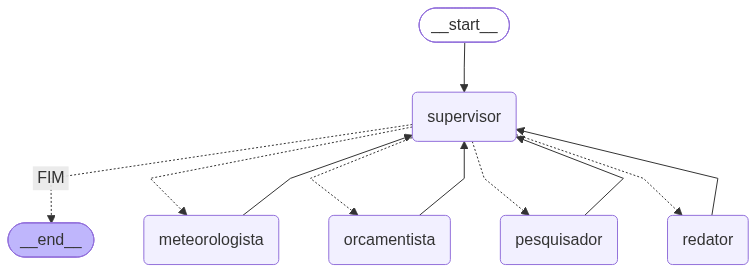

In [13]:
from IPython.display import Image, display

try:
    display(Image(equipe.get_graph().draw_mermaid_png()))
except Exception:
    print(equipe.get_graph().draw_mermaid())

---
## 9. Executando a equipe

A função abaixo roda a equipe com `stream`, que devolve o resultado nó a nó. Isso deixa a
**rota** visível: dá para acompanhar cada decisão do supervisor em vez de ver apenas a
resposta final.

In [14]:
def planejar(pedido: str):
    """Executa a equipe e mostra a rota escolhida pelo supervisor."""
    print(f"\n{'=' * 68}\nPEDIDO: {pedido}\n{'=' * 68}")

    rota = []
    for passo in equipe.stream(
        {"messages": [HumanMessage(pedido)], "ja_atuaram": []},
        {"recursion_limit": LIMITE_PASSOS},
    ):
        for no, saida in passo.items():
            if no == "supervisor":
                destino = saida["proximo"]
                print(f"\n[supervisor] -> {destino}")
                rota.append(destino)
            else:
                print(f"  [{no}] {saida['messages'][-1].content}")

    print(f"\nRota escolhida: {' -> '.join(rota)}")
    return rota

### Demonstração 1 — pedido simples

Só precisa de informação sobre o destino. A expectativa é que o supervisor acione apenas o
pesquisador e encerre.

In [15]:
rota_1 = planejar("O que tem para ver em Ouro Preto?")


PEDIDO: O que tem para ver em Ouro Preto?

[supervisor] -> pesquisador
  [pesquisador] Ouro Preto, em Minas Gerais, é um município de 1 250 km², com cerca de 78 000 habitantes, situado a 1 179 m de altitude. Seu centro histórico, preservado em estilo barroco, abriga igrejas, museus e casarões típicos. A cidade é reconhecida como Patrimônio Mundial da UNESCO, refletindo sua importância cultural e arquitetônica.

[supervisor] -> FIM

Rota escolhida: pesquisador -> FIM


### Demonstração 2 — pedido sobre o tempo

Mesma aplicação, pedido diferente: agora quem interessa é o meteorologista. O pesquisador
**não** é chamado.

In [16]:
rota_2 = planejar("Vou a Tiradentes amanha. Preciso levar guarda-chuva?")


PEDIDO: Vou a Tiradentes amanha. Preciso levar guarda-chuva?

[supervisor] -> meteorologista
  [meteorologista] Previsão para Tiradentes amanhã (2026‑10‑15):  
- Temperatura: 15,7 °C a 28,0 °C.  
- Chuva prevista: 4,4 mm.  
Recomendo levar guarda‑chuva.

[supervisor] -> FIM

Rota escolhida: meteorologista -> FIM


### Demonstração 3 — pedido completo

Aqui o pedido exige os três levantamentos mais o fechamento. A rota deve ficar visivelmente
mais longa que as anteriores.

In [18]:
rota_3 = planejar(
    "Vou a Ouro Preto neste fim de semana saindo de Lavras. "
    "O que visitar, como estara o tempo e quanto gasto de combustivel "
    "em 320 km com um carro que faz 12 km/l a R$ 6,10 o litro?"
)


PEDIDO: Vou a Ouro Preto neste fim de semana saindo de Lavras. O que visitar, como estara o tempo e quanto gasto de combustivel em 320 km com um carro que faz 12 km/l a R$ 6,10 o litro?

[supervisor] -> pesquisador
  [pesquisador] Ouro Preto, cidade histórica de Minas Gerais, foi capital da região colonial e hoje preserva arquitetura barroca e igrejas como São Francisco de Assis.  
Visite a Praça Tiradentes, o Museu da Inconfidência e o Convento da Penha.  
Passeie pelas ladeiras de pedra e descubra o artesanato local.  
A atmosfera de museus, cafés e galerias de arte faz da cidade um destino cultural imperdível.

[supervisor] -> meteorologista
  [meteorologista] Temperatura atual em Ouro Preto: 19,8 °C.  
2026‑10‑14: mín. 17 °C, máx. 25,5 °C, chuva 3 mm.  
2026‑10‑15: mín. 17,5 °C, máx. 29,3 °C, chuva 4 mm.  
2026‑10‑16: mín. 16,7 °C, máx. 26,5 °C, chuva 19,3 mm.

[supervisor] -> orcamentista
  [orcamentista] Combustível: 320 km ÷ 12 km/l × R$ 6,10 = R$ 162,67.

[supervisor] -> redat

### As três rotas lado a lado

Esta é a evidência de que a aplicação é um agente: **mesmo código, rotas diferentes**.

In [19]:
for i, rota in enumerate([rota_1, rota_2, rota_3], start=1):
    especialistas = [p for p in rota if p != "FIM"]
    print(f"Demonstracao {i}: {len(especialistas)} especialista(s) | "
          f"{' -> '.join(rota)}")

Demonstracao 1: 1 especialista(s) | pesquisador -> FIM
Demonstracao 2: 1 especialista(s) | meteorologista -> FIM
Demonstracao 3: 4 especialista(s) | pesquisador -> meteorologista -> orcamentista -> redator -> FIM


---
## 10. Agente ou pipeline?

A função abaixo resolve o mesmo problema sem agente nenhum: ela sempre busca o destino, sempre
consulta o clima e sempre resume, nessa ordem.

O teste que separa os dois é simples: **se eu tirar o LLM, o fluxo do programa muda?**

- No `pipeline`: não. A sequência está escrita no código.
- Na `equipe`: sim. Sem o supervisor não há quem decida a rota.

Pipeline não é ruim — é previsível e mais barato. Só não é agente.

In [20]:
def pipeline(destino: str):
    """Mesmo problema, sem agentes: a ordem esta fixa no codigo."""
    info = buscar_destino.invoke({"destino": destino})      # SEMPRE busca
    clima = consultar_clima.invoke({"cidade": destino})     # SEMPRE consulta
    return llm.invoke(                                      # SEMPRE resume
        f"Resuma em 3 linhas para um viajante:\n{info}\n{clima}"
    ).content


print(pipeline("Ouro Preto"))

Ouro Preto, Minas Gerais, fica a 100 km sudeste de Belo Horizonte, em altitude de 1 179 m, com cerca de 78 k habitantes.  
Hoje a temperatura é 19,8 °C, com 3 mm de chuva prevista.  
Para os próximos dias: 17–25,5 °C (3 mm), 17,5–29,3 °C (4 mm) e 16,7–26,5 °C (19,3 mm).


Repare no desperdício: na Demonstração 1 o usuário só queria saber o que visitar, mas o
pipeline consulta o clima de qualquer forma. O agente não fez essa chamada, porque o
supervisor julgou que ela não era necessária.

---
## 11. Conclusões

**A colaboração entre os agentes funcionou.** Cada especialista recebeu um papel estreito e
apenas as ferramentas do seu domínio, e o supervisor compôs as contribuições conforme o pedido.
As três demonstrações percorreram rotas diferentes com o mesmo código, que é o comportamento
esperado de um sistema multiagente — e não de um pipeline.

**As ferramentas são o que ancoram o agente na realidade.** O LLM nunca executa nada: ele
devolve um pedido estruturado dizendo qual função chamar e com quais argumentos, e quem executa
é o nosso código. Os `system_prompt` dos especialistas reforçam isso ao exigir o uso da
ferramenta em vez de resposta de memória — a previsão do tempo e o custo do combustível vêm de
dados reais, não de estimativa do modelo.

**Delimitar o escopo de cada agente é tão importante quanto atribuí-lo.** A primeira execução
revelou o problema de forma clara: recebendo o pedido completo, o pesquisador respondeu também
sobre clima e custo, calculando o combustível de cabeça e errando o valor — R$ 162,70 contra os
R$ 162,67 que a ferramenta devolve. Como a resposta parecia cobrir tudo, o supervisor encerrou
antes de acionar os demais. A correção teve duas frentes: restringir cada `system_prompt` com
proibições explícitas e reescrever a instrução do supervisor para verificar o pedido parte por
parte, considerando atendida apenas a parte que o especialista daquele domínio cobriu.

Esse episódio ilustra bem a natureza do sistema: o LLM tende a ser prestativo e responder o que
for perguntado, mesmo fora do seu papel. Num sistema multiagente isso quebra a divisão de
trabalho — e o sintoma não aparece como erro de execução, e sim como uma resposta plausível e
incorreta.

**O estado compartilhado precisa de disciplina.** O campo `ja_atuaram` é verificado tanto na
instrução do supervisor quanto no código do grafo, para que nenhum especialista seja acionado
duas vezes. Por ser o LLM quem decide a rota, o sistema é mais flexível e também menos
previsível que um fluxo fixo — o limite de passos deixa de ser detalhe e passa a ser proteção
necessária.

**Limitações e caminhos naturais.** A ferramenta de clima devolve sempre os três dias seguintes à execução. No pedido da Demonstração 3, que menciona o fim de semana, o meteorologista respondeu com a previsão de quarta a sexta — cobrir esse caso exigiria interpretar a data pedida e ajustar a janela da consulta. A aplicação também não guarda memória entre execuções, de modo que cada pedido começa do zero; um `checkpointer` com `thread_id` resolveria. E não há aprovação humana antes de ações sensíveis — com `interrupt`, o grafo pausaria e esperaria confirmação, o que seria indispensável se alguma ferramenta efetivamente reservasse ou comprasse algo.
